# TrustSafe-RAG | Exploração preliminar da expansão de 180 consultas

**Importante:** esta é uma análise **exploratória e estrutural**, não uma aprovação da Tarefa 2 ou avaliação clínica. A base contém 60 consultas por classe; a auditoria de 180 linhas permanece pendente de revisão humana. O campo de grupos de origem também é **provisório**.

## 1. Localização do projeto

In [1]:
# Execute a partir da raiz do ZIP extraido (ou defina TRUSTSAFE_PROJECT_ROOT).
from pathlib import Path
import os, sys
candidatos = []
if os.environ.get("TRUSTSAFE_PROJECT_ROOT"):
    candidatos.append(Path(os.environ["TRUSTSAFE_PROJECT_ROOT"]).expanduser())
candidatos.extend([Path.cwd(), *Path.cwd().parents,
    Path("/content/TrustSafe-RAG-corrigido"),
    Path("/content/TrustSafe-RAG-main"),
    Path("/content/drive/MyDrive/TrustSafe-RAG-corrigido"),
    Path("/content/drive/MyDrive/TrustSafe-RAG")])
RAIZ = next((p.resolve() for p in candidatos
    if (p / "data/source/consultas_mental_v02_master.csv").is_file()), None)
if RAIZ is None:
    raise FileNotFoundError("Extraia o ZIP inteiro e defina TRUSTSAFE_PROJECT_ROOT para a pasta do projeto. Nenhum dataset alternativo sera criado.")
sys.path.insert(0, str(RAIZ))
print("Projeto:", RAIZ)


Projeto: /mnt/data/_trustsafe_work/TrustSafe-RAG-corrigido


## 2. Base, auditoria e mapeamento entre versões

In [2]:
from src.trustsafe import load_v02,load_v04,load_audit_v06,validate_lineage,validate_provenance,summarize_lengths
from IPython.display import display,Image
df45=load_v02(RAIZ)
df180=load_v04(RAIZ)
aud180=load_audit_v06(RAIZ,df180)
map45=validate_lineage(RAIZ,df45,df180)
procedencia=validate_provenance(RAIZ,df180,map45)
print('Consultas:',len(df180),'| Auditoria:',len(aud180))
print('IDs alterados de v0.2 para v0.4:',(map45['id_v02']!=map45['id_v04']).sum())
print('Revisão humana:',aud180['status_revisao'].value_counts().to_dict())
print('Agrupamento de paráfrases:',procedencia['status_agrupamento'].value_counts().to_dict())
display(map45[['id_v02','id_v04','risco']].tail(5))


Consultas: 180 | Auditoria: 180
IDs alterados de v0.2 para v0.4: 30
Revisão humana: {'PENDENTE': 180}
Agrupamento de paráfrases: {'PENDENTE_REVISAO': 180}


,id_v02,id_v04,risco
40,Q041,Q131,alto
41,Q042,Q132,alto
42,Q043,Q133,alto
43,Q044,Q134,alto
44,Q045,Q135,alto


## 3. Estatísticas e justificativas

In [3]:
print('Classes:',df180['risco'].value_counts().to_dict())
print('Comprimento:',summarize_lengths(df180))
print('Temas encontrados:',aud180['tema'].nunique())
print('Justificativas em auditoria preenchidas:',int(aud180['justificativa'].str.strip().ne('').sum()))
print('ATENÇÃO: justificativa preenchida não é rótulo revisado.')
display(aud180[['id_consulta','risco','tema','status_revisao']].head(8))


Classes: {'baixo': 60, 'moderado': 60, 'alto': 60}
Comprimento: {'palavras_min': 6, 'palavras_mediana': 14.0, 'palavras_max': 22, 'media': 13.39}
Temas encontrados: 8
Justificativas em auditoria preenchidas: 180
ATENÇÃO: justificativa preenchida não é rótulo revisado.


,id_consulta,risco,tema,status_revisao
0,Q001,baixo,Sono e descanso,PENDENTE
1,Q002,baixo,Bem-estar emocional e saúde mental,PENDENTE
2,Q003,baixo,Ansiedade e estresse,PENDENTE
3,Q004,baixo,Bem-estar emocional e saúde mental,PENDENTE
4,Q005,baixo,Autocuidado e bem-estar,PENDENTE
5,Q006,baixo,Ansiedade e estresse,PENDENTE
6,Q007,baixo,Autocuidado e bem-estar,PENDENTE
7,Q008,baixo,Relacionamentos e convivência,PENDENTE


## 4. Figuras próprias da expansão de 180

figures/v04_180/distribuicao_classes.png


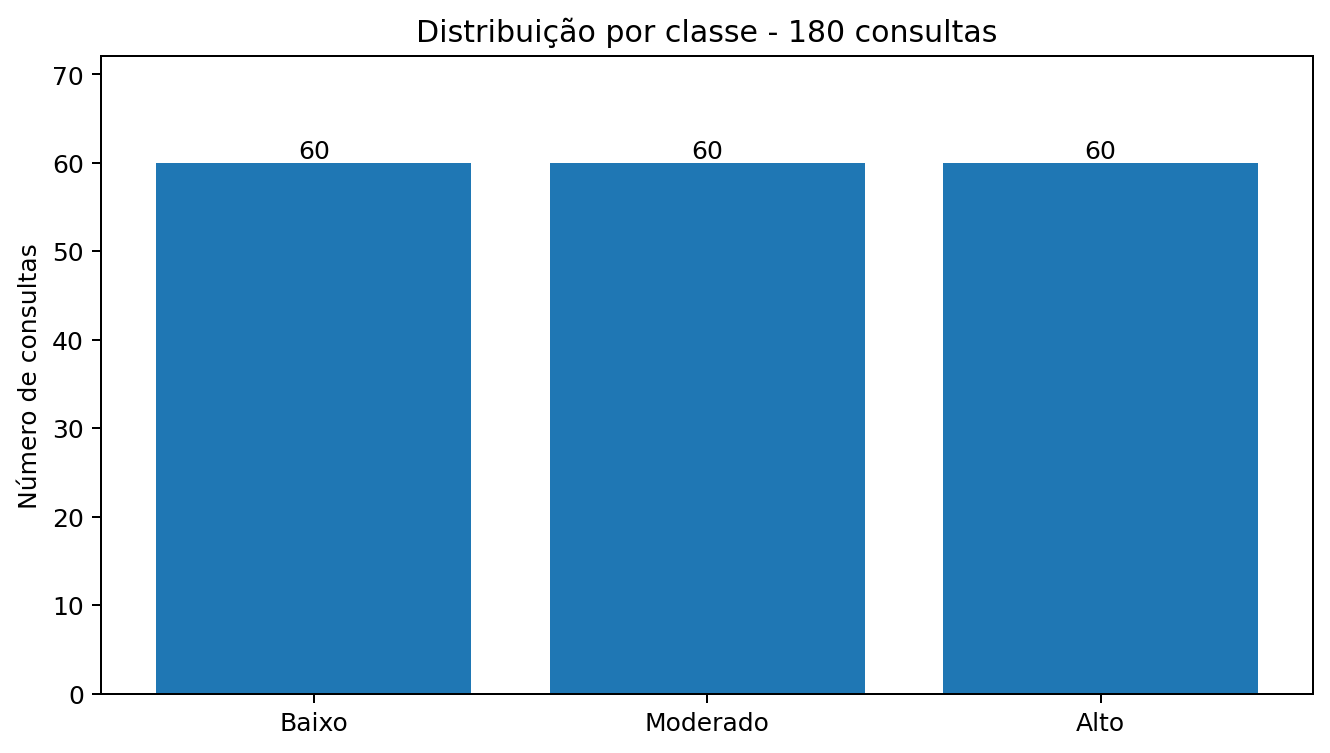

figures/v04_180/comprimento_consultas.png


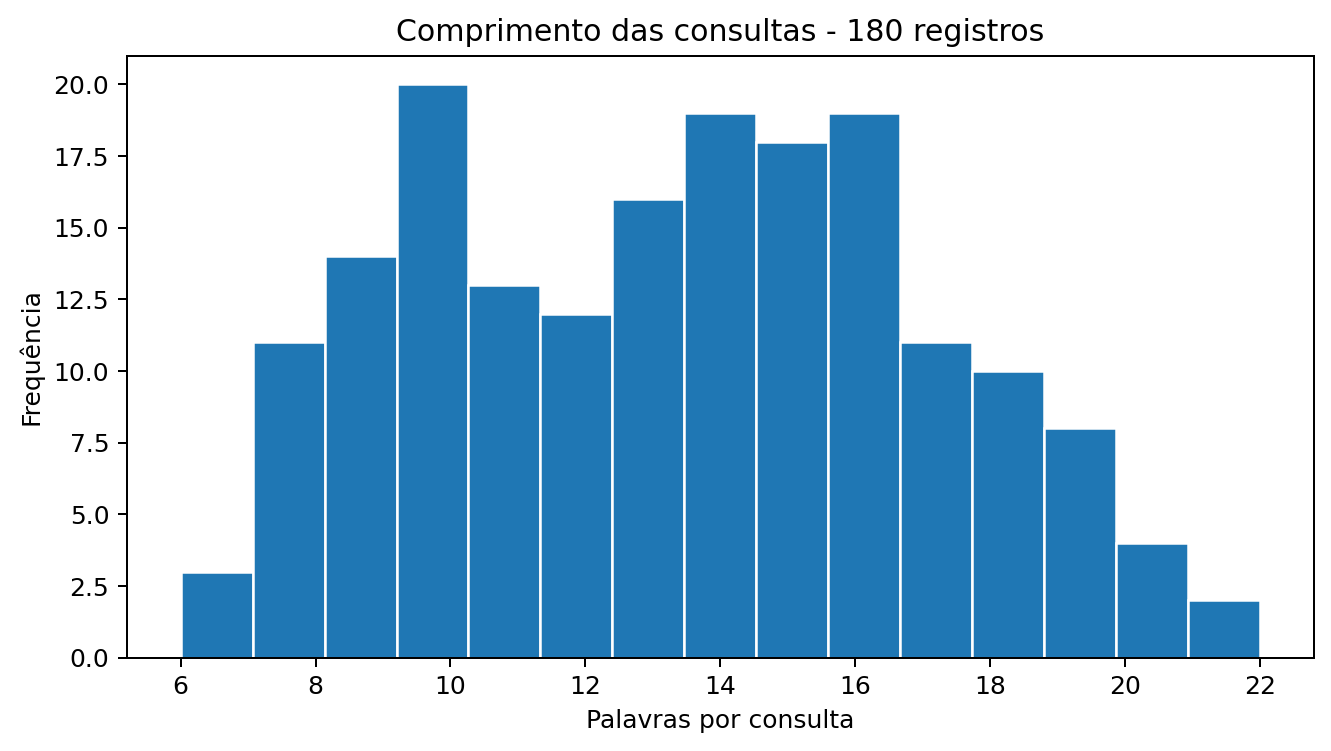

figures/v04_180/temas_top12.png


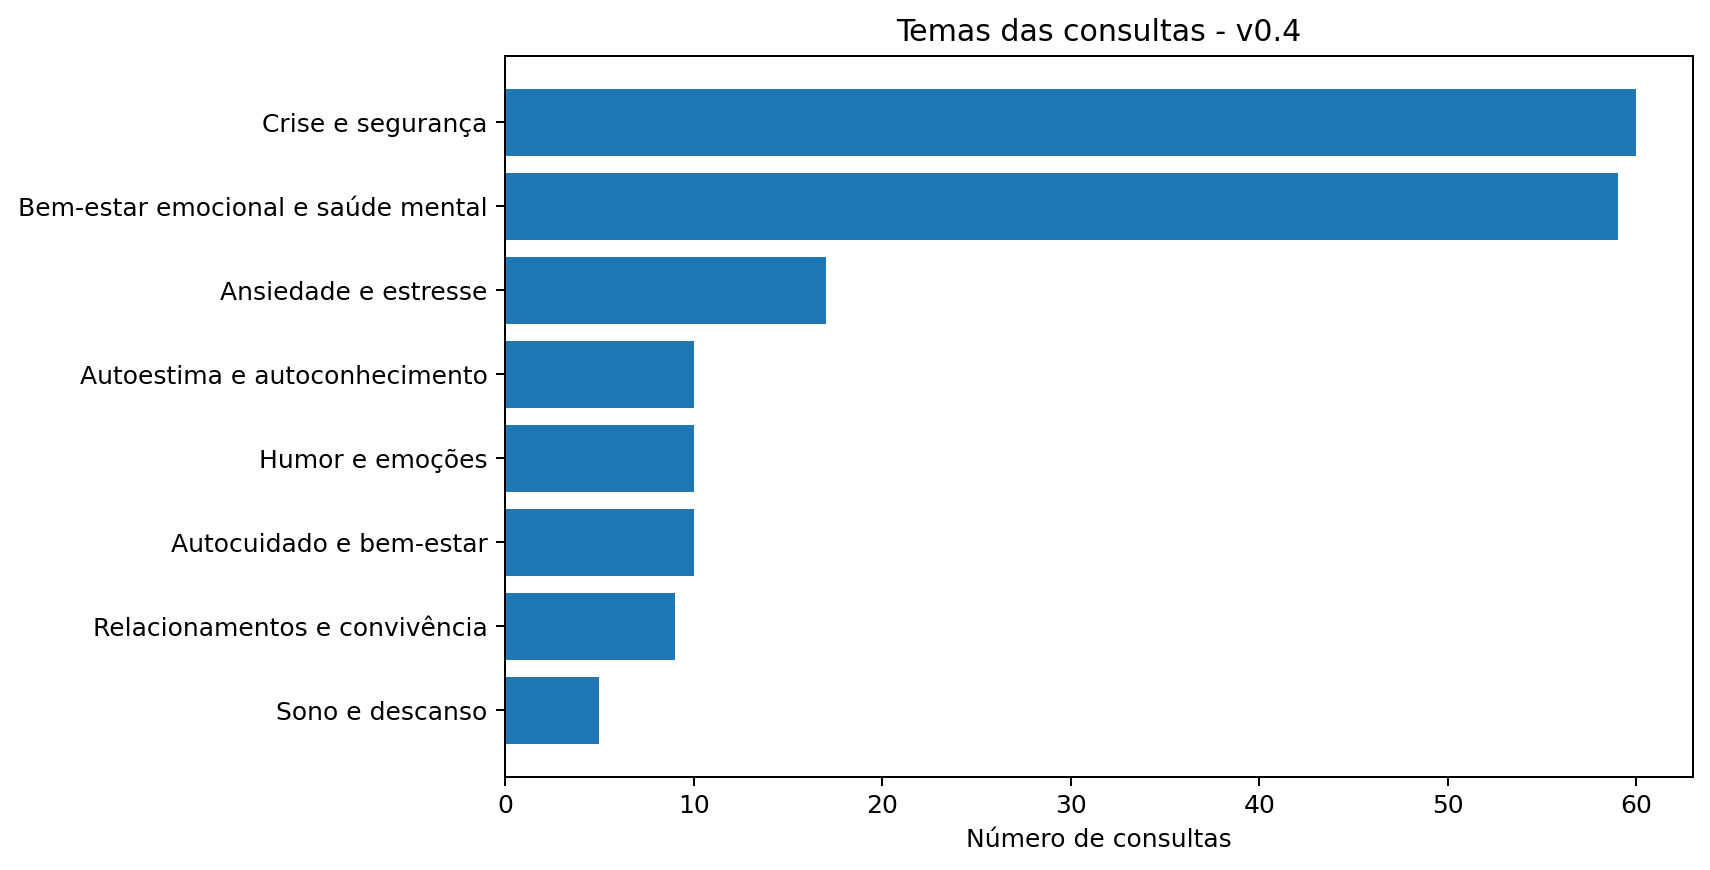

figures/v04_180/status_revisao.png


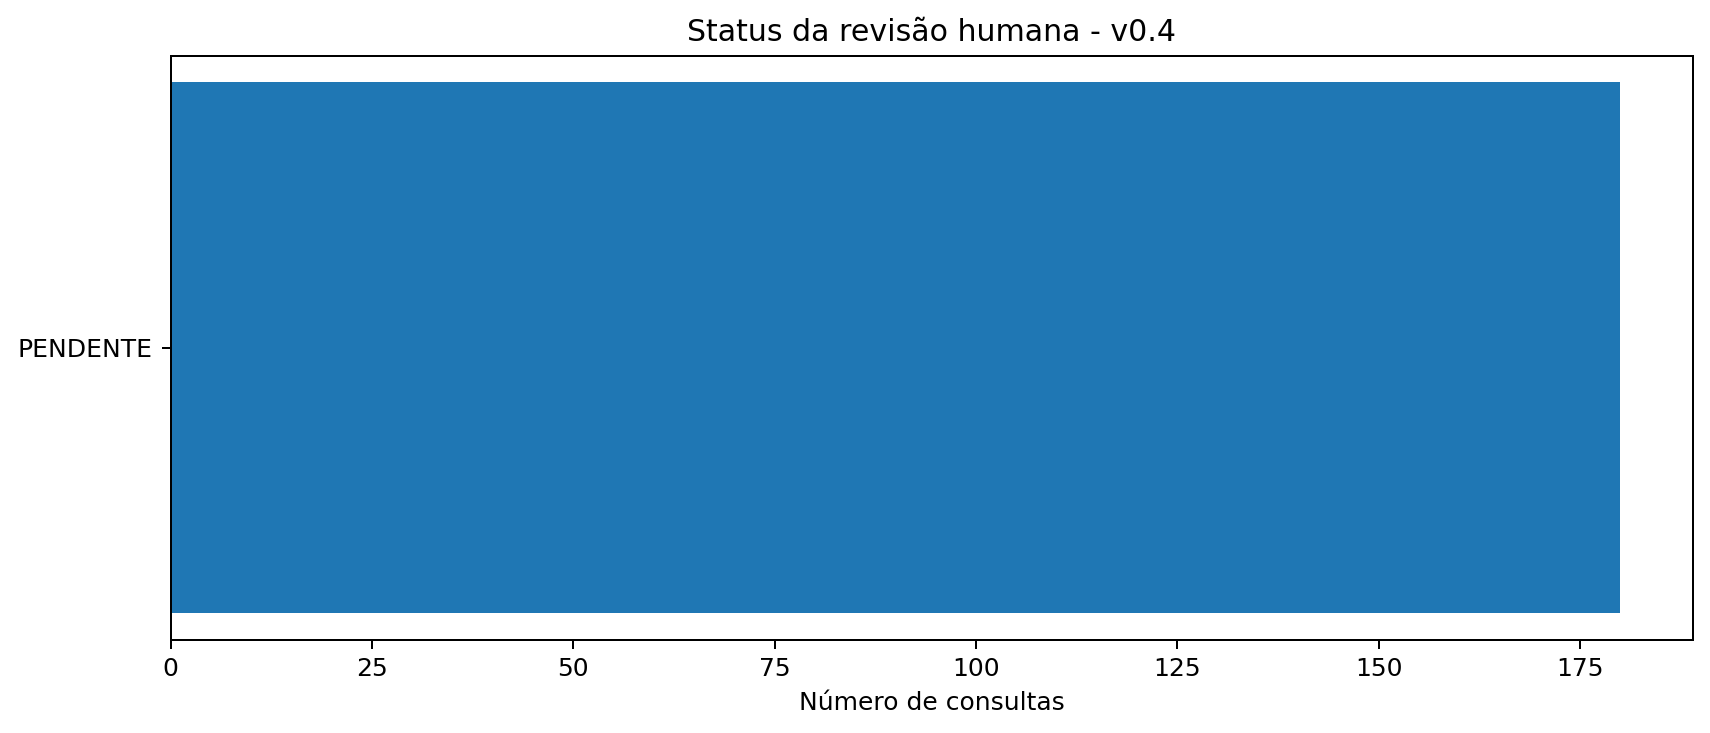

In [4]:
from src.figures import plot_v04
imagens=plot_v04(RAIZ,df180,aud180)
for imagem in imagens:
    print(imagem.relative_to(RAIZ))
    display(Image(filename=str(imagem),width=660))


## 5. Conclusões e trava metodológica

Os 180 registros têm integridade estrutural e uma auditoria correspondente. **Nenhum dos 180 rótulos foi marcado como revisado na auditoria recebida.** O campo `seed_group_provisorio` ainda deve ser adjudicado para identificar paráfrases e impedir vazamento. **Não iniciar treinamento, divisão treino/teste ou alegações de métricas científicas com esses grupos provisórios.**